In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual styling defaults
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Load dataset
df = pd.read_csv('retail_sales.csv.csv')

# Initial inspection
print("Dataset Shape:", df.shape)
print("\nData Types:")
print(df.dtypes)
print("\nMissing Values:")
print(df.isnull().sum())
print("\nFirst 5 Rows:")
df.head()

Dataset Shape: (1000, 9)

Data Types:
Transaction ID       int64
Date                object
Customer ID         object
Gender              object
Age                  int64
Product Category    object
Quantity             int64
Price per Unit       int64
Total Amount         int64
dtype: object

Missing Values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

First 5 Rows:


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [11]:
# Date column ko datetime format mein convert karein
if 'Date' in df.columns:
    df['Date'] = pd.to_datetime(df['Date'])

# Numerical columns ki descriptive statistics
num_cols = df.select_dtypes(include=[np.number]).columns
num_stats = df[num_cols].describe().T

# Median aur Mode add karein
num_stats['median'] = df[num_cols].median()
num_stats['mode'] = df[num_cols].mode().iloc[0]

# Complete statistical summary display karein
num_stats[['mean', 'median', 'mode', 'std', 'min', '50%', 'max']]

,mean,median,mode,std,min,50%,max
Transaction ID,500.500,500.5,1.0,288.819436,1.0,500.5,1000.0
Age,41.392,42.0,43.0,13.681430,18.0,42.0,64.0
Quantity,2.514,3.0,4.0,1.132734,1.0,3.0,4.0
Price per Unit,179.890,50.0,50.0,189.681356,25.0,50.0,500.0
Total Amount,456.000,135.0,50.0,559.997632,25.0,135.0,2000.0


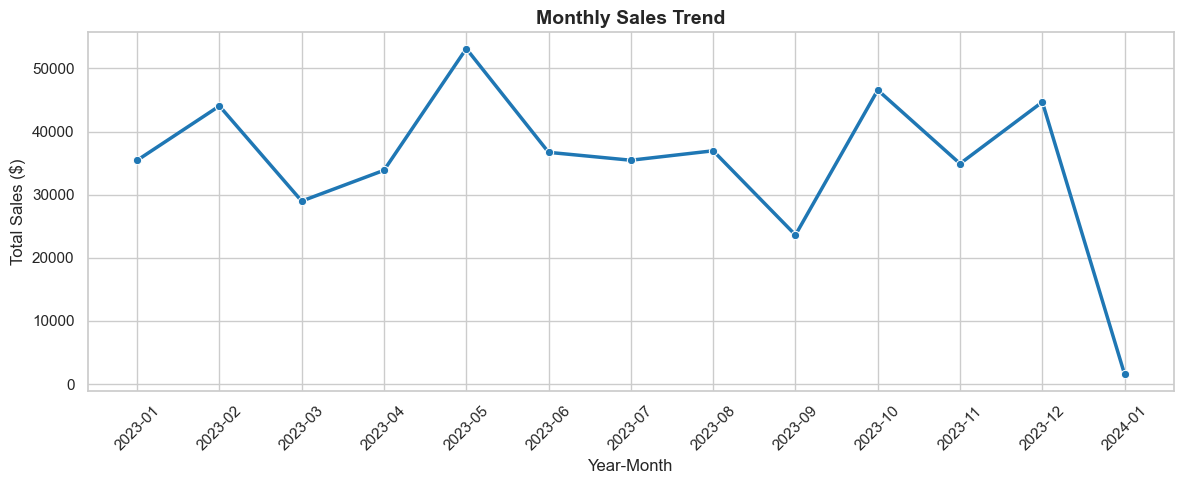

In [13]:
# Monthly aur Quarterly periods create karein
df['YearMonth'] = df['Date'].dt.to_period('M')
df['Quarter'] = df['Date'].dt.to_period('Q')

# Total Amount ya Quantity (jo bhi aapke column ka naam hai) ka monthly sum
monthly_sales = df.groupby('YearMonth')['Total Amount'].sum().reset_index()
monthly_sales['YearMonth'] = monthly_sales['YearMonth'].astype(str)

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly_sales, x='YearMonth', y='Total Amount', marker='o', color='#1f77b4', linewidth=2.5)
plt.xticks(rotation=45)
plt.title('Monthly Sales Trend', fontsize=14, fontweight='bold')
plt.xlabel('Year-Month')
plt.ylabel('Total Sales ($)')
plt.tight_layout()
plt.show()

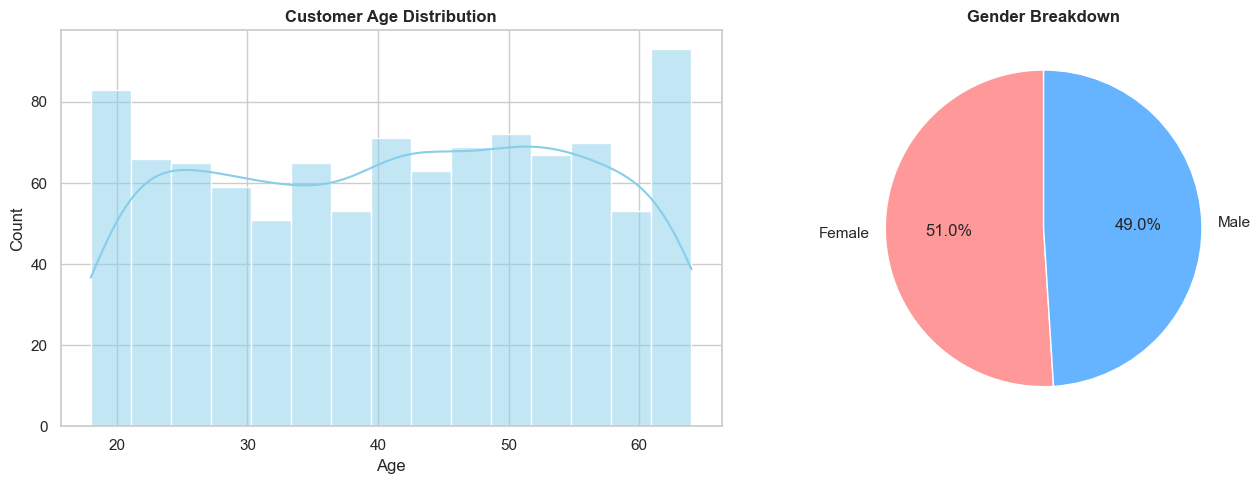

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Age Distribution
sns.histplot(df['Age'], kde=True, ax=axes[0], color='skyblue', bins=15)
axes[0].set_title('Customer Age Distribution', fontsize=12, fontweight='bold')

# Gender Breakdown
if 'Gender' in df.columns:
    gender_counts = df['Gender'].value_counts()
    axes[1].pie(gender_counts, labels=gender_counts.index, autopct='%1.1f%%', colors=['#ff9999','#66b3ff'], startangle=90)
    axes[1].set_title('Gender Breakdown', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

C:\Users\USER\AppData\Local\Temp\ipykernel_11824\2866333333.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=category_revenue, x='Total Amount', y=category_col, palette='Blues_r')


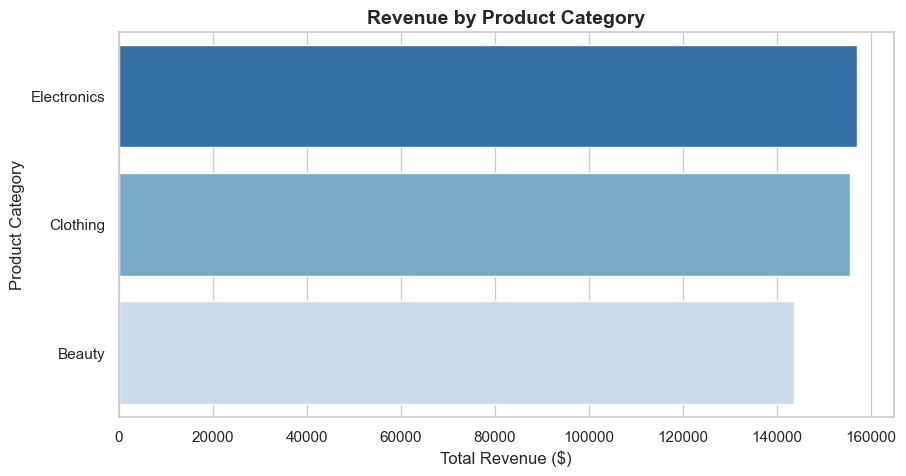

In [17]:
category_col = 'Product Category' if 'Product Category' in df.columns else 'Category'

category_revenue = df.groupby(category_col)['Total Amount'].sum().sort_values(ascending=False).reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(data=category_revenue, x='Total Amount', y=category_col, palette='Blues_r')
plt.title('Revenue by Product Category', fontsize=14, fontweight='bold')
plt.xlabel('Total Revenue ($)')
plt.ylabel('Product Category')
plt.show()

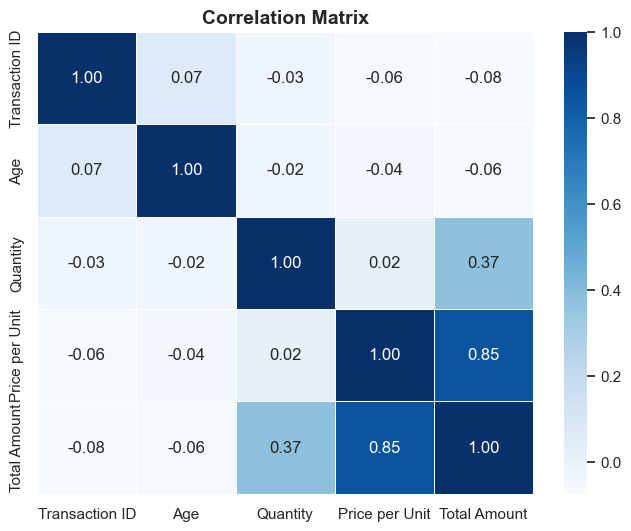

C:\Users\USER\AppData\Local\Temp\ipykernel_11824\445080395.py:10: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot_table = df.pivot_table(values='Total Amount', index='Age Group', columns=category_col, aggfunc='mean')


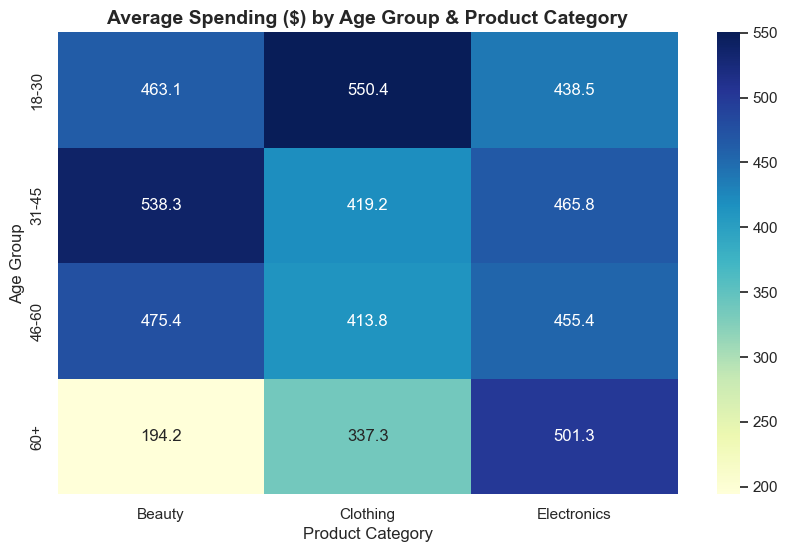

In [19]:
# 1. Correlation Heatmap
plt.figure(figsize=(8, 6))
numeric_df = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, cmap='Blues', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix', fontsize=14, fontweight='bold')
plt.show()

# 2. Custom Insight: Average Spending by Age Group & Category
df['Age Group'] = pd.cut(df['Age'], bins=[18, 30, 45, 60, 100], labels=['18-30', '31-45', '46-60', '60+'])
pivot_table = df.pivot_table(values='Total Amount', index='Age Group', columns=category_col, aggfunc='mean')

plt.figure(figsize=(10, 6))
sns.heatmap(pivot_table, annot=True, fmt='.1f', cmap='YlGnBu')
plt.title('Average Spending ($) by Age Group & Product Category', fontsize=14, fontweight='bold')
plt.show()

In [ ]:
## Conclusion & Business Recommendations

1. **Seasonal Inventory Planning:Proactively replenish stock ahead of peak sales months to prevent stockouts and capitalize on high-demand periods.
2. **Targeted Marketing Campaigns: Leverage customer demographic insights (age groups and gender breakdown) to run highly tailored ad campaigns for the most profitable audience segments.
3. **Product Bundling Strategy: Package lower-performing product categories together with top-selling items as bundle deals to increase the overall Average Order Value (AOV).